<a href="https://colab.research.google.com/github/AjinkyaSar/Centralized-repository-shipping_calculations/blob/main/Loan_Default_Classification_and_Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, roc_auc_score, roc_curve

In [ ]:
df = pd.read_excel('/content/Loan_Default_Dataset.xlsx')
display(df.head())
print(df.info())

,Loan_ID,LoanAmount,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,3509.4,1,0,0,1,0,5849,0.0,360,1,1,Y
1,LP001003,128.0,1,1,1,1,0,4583,1508.0,360,1,3,N
2,LP001005,66.0,1,1,0,1,1,3000,0.0,360,1,1,Y
3,LP001006,120.0,1,1,0,2,0,2583,2358.0,360,1,1,Y
4,LP001008,141.0,1,0,0,1,0,6000,0.0,360,1,1,Y


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 564 entries, 0 to 563
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            564 non-null    object 
 1   LoanAmount         564 non-null    float64
 2   Gender             564 non-null    int64  
 3   Married            564 non-null    int64  
 4   Dependents         564 non-null    int64  
 5   Education          564 non-null    int64  
 6   Self_Employed      564 non-null    int64  
 7   ApplicantIncome    564 non-null    int64  
 8   CoapplicantIncome  564 non-null    float64
 9   Loan_Amount_Term   564 non-null    int64  
 10  Credit_History     564 non-null    int64  
 11  Property_Area      564 non-null    int64  
 12  Loan_Status        564 non-null    object 
dtypes: float64(2), int64(9), object(2)
memory usage: 57.4+ KB
None


In [ ]:
df = df.drop('Loan_ID', axis=1)
display(df.head())

,LoanAmount,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,3509.4,1,0,0,1,0,5849,0.0,360,1,1,Y
1,128.0,1,1,1,1,0,4583,1508.0,360,1,3,N
2,66.0,1,1,0,1,1,3000,0.0,360,1,1,Y
3,120.0,1,1,0,2,0,2583,2358.0,360,1,1,Y
4,141.0,1,0,0,1,0,6000,0.0,360,1,1,Y


In [ ]:
display(df.isnull().sum())

,0
LoanAmount,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
ApplicantIncome,0
CoapplicantIncome,0
Loan_Amount_Term,0
Credit_History,0


In [ ]:
duplicate_rows = df[df.duplicated()]
display(duplicate_rows)

,LoanAmount,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status


In [ ]:
df['Loan_Status'] = df['Loan_Status'].map({'Y': 1, 'N': 0})
display(df.head())

,LoanAmount,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,3509.4,1,0,0,1,0,5849,0.0,360,1,1,1
1,128.0,1,1,1,1,0,4583,1508.0,360,1,3,0
2,66.0,1,1,0,1,1,3000,0.0,360,1,1,1
3,120.0,1,1,0,2,0,2583,2358.0,360,1,1,1
4,141.0,1,0,0,1,0,6000,0.0,360,1,1,1


In [ ]:
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

print("Shape of features (X):", X.shape)
print("Shape of target (y):", y.shape)

Shape of features (X): (564, 11)
Shape of target (y): (564,)


In [ ]:
from imblearn.over_sampling import SMOTE

# Initialize SMOTE
smote_full = SMOTE(random_state=42)

# Apply SMOTE to the entire dataset (X and y)
# **Caution: This is generally not recommended due to data leakage**
X_resampled_full, y_resampled_full = smote_full.fit_resample(X, y)

print("Shape of original dataset (X):", X.shape)
print("Shape of resampled dataset (X_resampled_full):", X_resampled_full.shape)
print("Shape of original target (y):", y.shape)
print("Shape of resampled target (y_resampled_full):", y_resampled_full.shape)

Shape of original dataset (X): (564, 11)
Shape of resampled dataset (X_resampled_full): (770, 11)
Shape of original target (y): (564,)
Shape of resampled target (y_resampled_full): (770,)


In [ ]:
from sklearn.model_selection import train_test_split

# Split the resampled dataset into training and testing sets
# Using a test size of 20% and a random state for reproducibility
X_train_resampled, X_test_resampled, y_train_resampled, y_test_resampled = train_test_split(
    X_resampled_full, y_resampled_full, test_size=0.2, random_state=42, stratify=y_resampled_full
)

print("Shape of resampled training features:", X_train_resampled.head)
print("Shape of resampled testing features:", X_test_resampled.shape)
print("Shape of resampled training target:", y_train_resampled.shape)
print("Shape of resampled testing target:", y_test_resampled.shape)

Shape of resampled training features: <bound method NDFrame.head of      LoanAmount  Gender  Married  Dependents  Education  Self_Employed  \
176  164.000000       1        0           0          1              0   
71   113.000000       1        0           0          1              0   
108  154.000000       2        1           0          1              0   
86   122.000000       1        0           0          1              0   
547  187.000000       1        1           2          2              1   
..          ...     ...      ...         ...        ...            ...   
109  175.000000       1        1           0          1              0   
597   76.661015       2        0           0          1              0   
303  117.000000       1        0           1          1              0   
23   191.000000       1        1           0          1              1   
82   175.000000       1        1           0          1              0   

     ApplicantIncome  CoapplicantIncome  Lo

In [ ]:
X_test_resampled.head()

,LoanAmount,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,Loan_Amount_Term,Credit_History,Property_Area
698,166.329086,1,0,0,1,0,8396,0.000000,360,1,1
258,158.000000,1,0,1,2,1,4053,2426.000000,360,0,1
184,90.000000,1,1,1,2,0,2600,2500.000000,360,1,2
700,162.281801,1,0,0,1,0,11618,0.000000,360,1,2
680,165.547171,1,1,0,1,0,3642,2803.586678,360,0,1


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train_resampled_processed = scaler.fit_transform(X_train_resampled)

# Transform test data using training parameters
X_test_resampled_processed = scaler.transform(X_test_resampled)


In [ ]:
import statsmodels.api as sm

# Combine X_train_resampled and y_train_resampled to easily drop rows with missing values
train_data_resampled = pd.concat([X_train_resampled, y_train_resampled], axis=1)

# Drop rows with any missing values
train_data_resampled_cleaned = train_data_resampled.dropna()

# Separate X_train_resampled and y_train_resampled again
X_train_resampled_cleaned = train_data_resampled_cleaned.drop('Loan_Status', axis=1)
y_train_resampled_cleaned = train_data_resampled_cleaned['Loan_Status']

# Add a constant to the cleaned features
X_train_resampled_sm = sm.add_constant(X_train_resampled_cleaned)
X_test_resampled_sm = sm.add_constant(X_test_resampled)

# Fit the Logistic Regression model using the cleaned training data
model_sm = sm.Logit(y_train_resampled_cleaned, X_train_resampled_sm)
results_sm = model_sm.fit()

print(results_sm.summary())

# Generate predictions on the test set
y_pred_resampled_sm = results_sm.predict(X_test_resampled_sm)

Optimization terminated successfully.
         Current function value: 0.446132
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            Loan_Status   No. Observations:                  616
Model:                          Logit   Df Residuals:                      604
Method:                           MLE   Df Model:                           11
Date:                Tue, 02 Sep 2025   Pseudo R-squ.:                  0.3564
Time:                        16:20:41   Log-Likelihood:                -274.82
converged:                       True   LL-Null:                       -426.98
Covariance Type:            nonrobust   LLR p-value:                 1.076e-58
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                -4.2787      0.976     -4.384      0.000      -6.192      -2.366
LoanAmou

In [ ]:
import statsmodels.api as sm

def backward_elimination(X, y, significance_level=0.05):
    """Perform backward elimination on logistic regression using p-values."""
    X_be = sm.add_constant(X)  # Add intercept
    removed_features = []

    while True:
        model = sm.Logit(y, X_be).fit(disp=False)
        p_values = model.pvalues.drop("const", errors="ignore")  # ignore intercept
        max_p = p_values.max()
        worst_feature = p_values.idxmax()

        # Check if worst feature exceeds significance threshold
        if max_p > significance_level:
            print(f"Dropping '{worst_feature}' (p-value={max_p:.4f})")
            X_be = X_be.drop(columns=[worst_feature])
            removed_features.append((worst_feature, float(max_p)))
        else:
            break

    final_model = sm.Logit(y, X_be).fit(disp=False)
    return X_be, final_model, removed_features

# Apply backward elimination on your cleaned training set
X_be, final_model, removed = backward_elimination(X_train_resampled_cleaned, y_train_resampled_cleaned)

print("\nRemoved features:")
for f, p in removed:
    print(f"- {f}: p={p:.4f}")

print("\nFinal model summary:")
print(final_model.summary())


Dropping 'ApplicantIncome' (p-value=0.8608)
Dropping 'Education' (p-value=0.7418)
Dropping 'Dependents' (p-value=0.6660)
Dropping 'Loan_Amount_Term' (p-value=0.5972)
Dropping 'Property_Area' (p-value=0.5390)
Dropping 'CoapplicantIncome' (p-value=0.4396)
Dropping 'Self_Employed' (p-value=0.3541)
Dropping 'Gender' (p-value=0.1067)

Removed features:
- ApplicantIncome: p=0.8608
- Education: p=0.7418
- Dependents: p=0.6660
- Loan_Amount_Term: p=0.5972
- Property_Area: p=0.5390
- CoapplicantIncome: p=0.4396
- Self_Employed: p=0.3541
- Gender: p=0.1067

Final model summary:
                           Logit Regression Results                           
Dep. Variable:            Loan_Status   No. Observations:                  616
Model:                          Logit   Df Residuals:                      612
Method:                           MLE   Df Model:                            3
Date:                Tue, 02 Sep 2025   Pseudo R-squ.:                  0.3503
Time:                        1

Accuracy: 0.7922077922077922

Classification Report:
               precision    recall  f1-score   support

           0      0.925     0.636     0.754        77
           1      0.723     0.948     0.820        77

    accuracy                          0.792       154
   macro avg      0.824     0.792     0.787       154
weighted avg      0.824     0.792     0.787       154

ROC-AUC: 0.8851408331927811


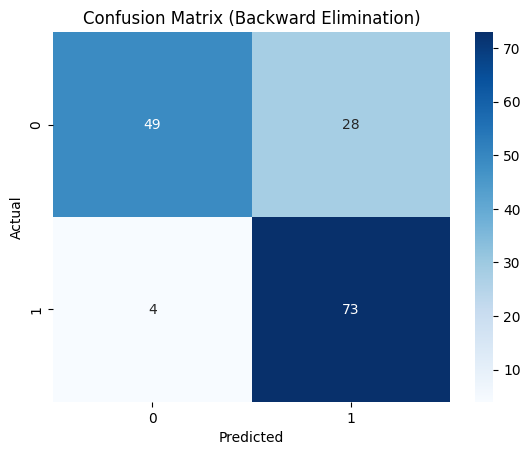

In [ ]:
# Keep only the selected features for test set
selected_features = [col for col in X_be.columns if col != "const"]

X_test_selected = sm.add_constant(X_test_resampled[selected_features], has_constant="add")

# Predict on test data
y_pred_prob = final_model.predict(X_test_selected)
y_pred = (y_pred_prob >= 0.5).astype(int)

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

print("Accuracy:", accuracy_score(y_test_resampled, y_pred))
print("\nClassification Report:\n", classification_report(y_test_resampled, y_pred, digits=3))
print("ROC-AUC:", roc_auc_score(y_test_resampled, y_pred_prob))

# Confusion matrix heatmap
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_resampled, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix (Backward Elimination)")
plt.show()


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
import numpy as np

# Remove 'const' because sklearn LogisticRegression adds intercept by default
X_be_sklearn = X_be.drop(columns=["const"], errors="ignore")
y_be = y_train_resampled_cleaned  # same target used for backward elimination

# Define model
log_reg = LogisticRegression(max_iter=1000, solver="liblinear")

# Define stratified k-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Accuracy
accuracy_scores = cross_val_score(log_reg, X_be_sklearn, y_be, cv=cv, scoring="accuracy")

# ROC-AUC
roc_auc_scores = cross_val_score(log_reg, X_be_sklearn, y_be, cv=cv, scoring="roc_auc")

# Print results with range
print("Cross-Validation Results (Final Backward Elimination Dataset):")
print(f"Accuracy: {accuracy_scores.mean():.4f} (Range: {accuracy_scores.min():.4f} - {accuracy_scores.max():.4f})")
print(f"ROC-AUC: {roc_auc_scores.mean():.4f} (Range: {roc_auc_scores.min():.4f} - {roc_auc_scores.max():.4f})")


Cross-Validation Results (Final Backward Elimination Dataset):
Accuracy: 0.7824 (Range: 0.6911 - 0.8306)
ROC-AUC: 0.8382 (Range: 0.8025 - 0.8721)


<h1>Decision Tree for significant variables</h1>

Decision Tree - Training Accuracy: 0.800
Decision Tree - Testing Accuracy: 0.812


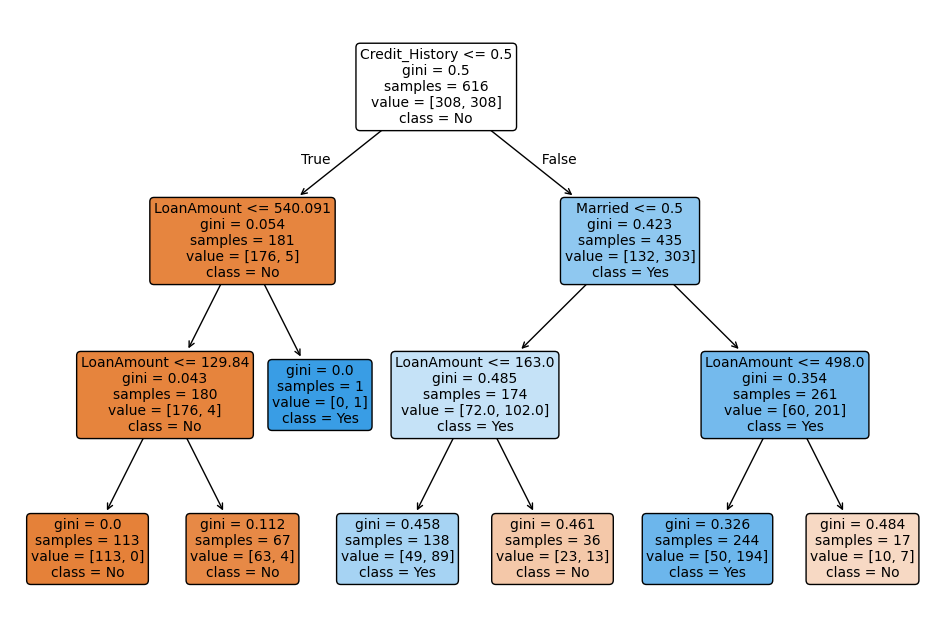

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Select only the important features
selected_features = ["LoanAmount", "Married", "Credit_History"]

# Train Decision Tree
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(X_train_resampled_cleaned[selected_features], y_train_resampled_cleaned)

# Accuracy check
train_acc = dt_model.score(X_train_resampled_cleaned[selected_features], y_train_resampled_cleaned)
test_acc = dt_model.score(X_test_resampled[selected_features], y_test_resampled)

print(f"Decision Tree - Training Accuracy: {train_acc:.3f}")
print(f"Decision Tree - Testing Accuracy: {test_acc:.3f}")

# Plot the tree
plt.figure(figsize=(12, 8))
plot_tree(
    dt_model,
    feature_names=selected_features,
    class_names=["No", "Yes"],  # adjust if your target encoding is different
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Input widgets
loan_amount = widgets.FloatText(
    description="LoanAmount:",
    style={'description_width': 'initial'}
)

married = widgets.Dropdown(
    options=[("No", 0), ("Yes", 1)],
    description="Married:",
    style={'description_width': 'initial'}
)

credit_history = widgets.Dropdown(
    options=[("Bad/No Credit", 0), ("Good", 1)],
    description="Credit_History:",
    style={'description_width': 'initial'}
)

# Button
predict_button = widgets.Button(
    description="Predict Loan Decision",
    button_style="success"
)

# Output
output = widgets.Output()

# Prediction function
def on_predict_clicked(b):
    with output:
        clear_output()
        X_new = [[loan_amount.value, married.value, credit_history.value]]
        pred = dt_model.predict(X_new)[0]

        if pred == 1:
            print("✅ YES – Give Loan")
        else:
            print("❌ NO – Reject Loan")

predict_button.on_click(on_predict_clicked)

# Display
display(loan_amount, married, credit_history, predict_button, output)


FloatText(value=0.0, description='LoanAmount:', style=DescriptionStyle(description_width='initial'))

Dropdown(description='Married:', options=(('No', 0), ('Yes', 1)), style=DescriptionStyle(description_width='in…

Dropdown(description='Credit_History:', options=(('Bad/No Credit', 0), ('Good', 1)), style=DescriptionStyle(de…

Button(button_style='success', description='Predict Loan Decision', style=ButtonStyle())

Output()

<h1>Decision Tree with all variables</h1>

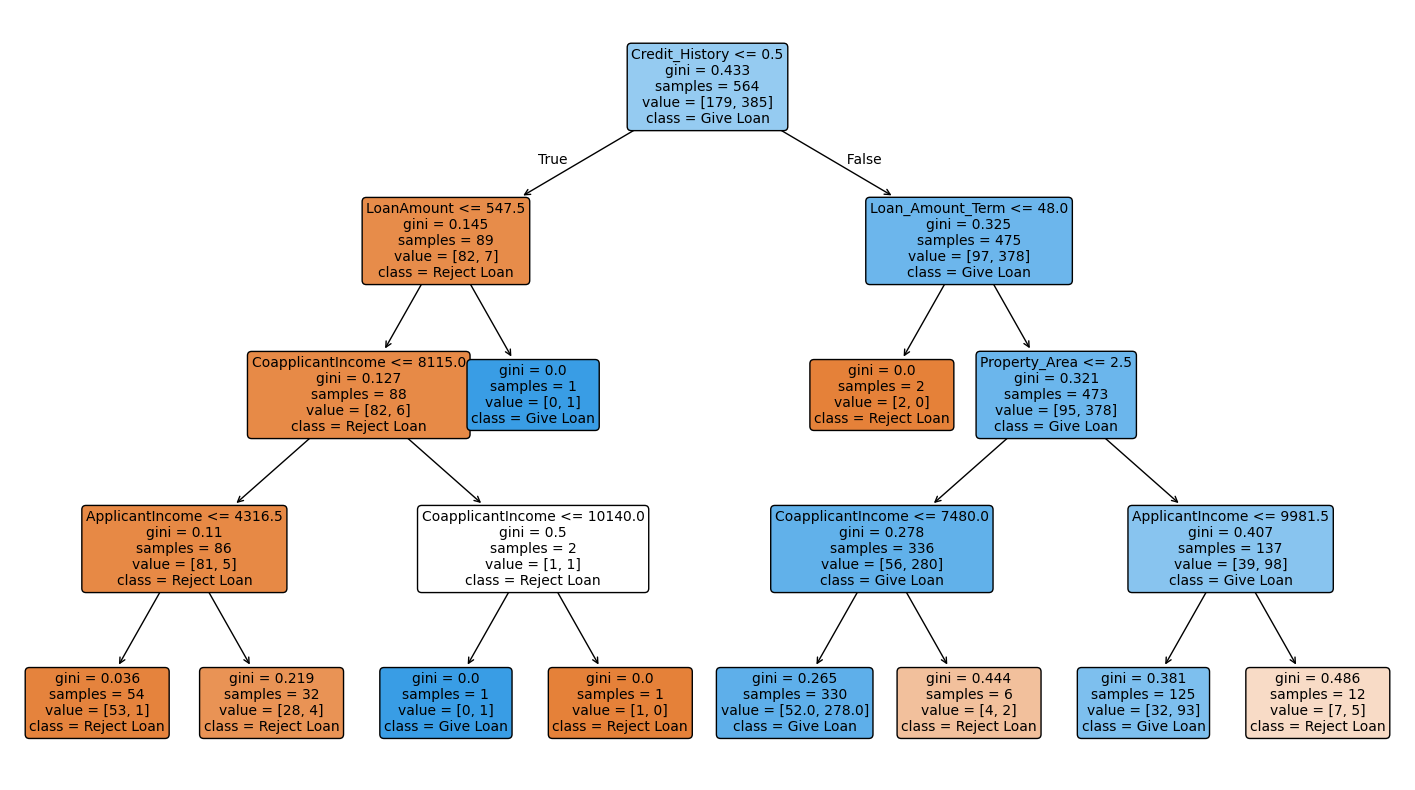

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

# Assuming your target column is named 'loan_status' (adjust if different)
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

# Train a Decision Tree on the full dataset
dt_full = DecisionTreeClassifier(
    criterion="gini",   # or "entropy"
    max_depth=4,        # keep tree small for visualization
    random_state=42
)
dt_full.fit(X, y)

# Plot decision tree
plt.figure(figsize=(18,10))
plot_tree(
    dt_full,
    feature_names=X.columns,
    class_names=["Reject Loan", "Give Loan"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.show()


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from sklearn.tree import DecisionTreeClassifier

# Split into features and target
X = df.drop("Loan_Status", axis=1)
y = df["Loan_Status"]

# Train Decision Tree on the whole dataset
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X, y)

# Create widget inputs dynamically for each feature
input_widgets = {}
for col in X.columns:
    if X[col].dtype == "object":  # categorical features
        input_widgets[col] = widgets.Dropdown(
            options=list(df[col].unique()),
            description=col,
            style={'description_width': 'initial'}
        )
    else:  # numeric features
        input_widgets[col] = widgets.FloatText(
            description=col,
            style={'description_width': 'initial'}
        )

# Prediction button
button = widgets.Button(description="Predict Loan Status", button_style="success")
output = widgets.Output()

# Define prediction function
def on_button_click(b):
    with output:
        clear_output()
        # Collect input values
        input_data = {col: [w.value] for col, w in input_widgets.items()}
        input_df = pd.DataFrame(input_data)

        # If categorical encoding is required, ensure same preprocessing is applied as training
        # (For simplicity assuming df is already numeric or label encoded)

        prediction = dt_model.predict(input_df)[0]
        if prediction == 1:
            print("✅ Yes: Give Loan")
        else:
            print("❌ No: Reject Loan")

button.on_click(on_button_click)

# Display all widgets
for w in input_widgets.values():
    display(w)
display(button, output)


FloatText(value=0.0, description='LoanAmount', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Gender', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Married', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Dependents', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Education', style=DescriptionStyle(description_width='initial'))

...

FloatText(value=0.0, description='Loan_Amount_Term', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Credit_History', style=DescriptionStyle(description_width='initial'))

FloatText(value=0.0, description='Property_Area', style=DescriptionStyle(description_width='initial'))

Button(button_style='success', description='Predict Loan Status', style=ButtonStyle())

Output()